In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
import yfinance as yf

In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'PETR4.SA'

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base.tail(10)

[PETR4.SA] Cache existente cobre de 2020-01-02 a 2025-06-02.
[PETR4.SA] Cache cobre período solicitado (2022-12-15 a 2025-06-02).
[PETR4.SA] Retornando 613 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20211215_20250603.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-02.
[^BVSP] Cache cobre período solicitado (2022-12-15 a 2025-06-02).
[^BVSP] Retornando 613 linhas para o período solicitado.


,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,...,atr_pct,tr_pct,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov
data,,,,,,,,,,,,,,,,,,,,,
2025-05-20,32.049999,32.410000,31.950001,32.110001,33485800,0.004065,0.009093,53.978882,-0.131027,-0.461730,...,0.023732,0.014326,14.75,0.43,5.6620,139636.0000,140244.00000,138966.000000,140110.000,9650800
2025-05-21,32.209999,32.389999,31.690001,31.750000,28724100,-0.011211,0.010671,50.244919,-0.106271,-0.390638,...,0.023862,0.022047,14.75,0.43,5.6571,140109.0000,140109.00000,137538.000000,137881.000,10150400
2025-05-22,31.639999,31.650000,31.209999,31.330000,42207300,-0.013228,0.011511,46.227243,-0.119168,-0.336344,...,0.023685,0.017236,14.75,0.43,5.6390,137881.0000,138837.00000,137088.000000,137273.000,13223200
2025-05-23,31.090000,31.400000,30.870001,31.400000,25732400,0.002234,0.011406,46.988074,-0.122331,-0.293541,...,0.023150,0.016879,14.75,0.43,5.6932,137273.0000,137824.00000,134997.000000,137824.000,10682600
2025-05-26,31.459999,31.530001,31.139999,31.299999,21277100,-0.003185,0.008319,45.987034,-0.131392,-0.261112,...,0.022455,0.012460,14.75,0.43,5.6619,137824.0000,138800.00000,137795.000000,138136.000,5553800
2025-05-27,31.520000,31.670000,31.360001,31.530001,34361500,0.007348,0.006862,48.694370,-0.118646,-0.232618,...,0.021537,0.011735,14.75,0.43,5.6539,138136.0000,140382.00000,138136.000000,139541.000,11187800
2025-05-28,31.670000,31.719999,31.430000,31.430000,30516200,-0.003172,0.006661,47.577754,-0.115285,-0.209152,...,0.020722,0.009227,14.75,0.43,5.6936,139541.0000,139547.00000,138580.000000,138888.000,9735000
2025-05-29,31.480000,31.500000,31.049999,31.240000,20778800,-0.006045,0.006813,45.445431,-0.126495,-0.192620,...,0.020387,0.014405,14.75,0.43,5.6559,138869.0000,139108.00000,137993.000000,138534.000,8826400
2025-05-30,31.150000,31.270000,30.900000,30.900000,45127700,-0.010883,0.006897,41.832406,-0.160958,-0.186288,...,0.019995,0.011974,14.75,0.43,5.7087,138546.0000,138637.00000,136726.000000,137027.000,15141600


## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-05-20,0.762035,0.023732,0.459999,0.014326
2025-05-21,0.757604,0.023862,0.699999,0.022047
2025-05-22,0.742061,0.023685,0.540001,0.017236
2025-05-23,0.726914,0.023150,0.529999,0.016879
2025-05-26,0.702848,0.022455,0.390001,0.012460
2025-05-27,0.679074,0.021537,0.370001,0.011735
2025-05-28,0.651283,0.020722,0.289999,0.009227
2025-05-29,0.636905,0.020387,0.450001,0.014405
2025-05-30,0.617841,0.019995,0.370001,0.011974


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 2.01%
Valorização sugerida: 3.02%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [14]:
valorizacao = 0.03
DIAS_FUTURO = 5  # dias futuros para buscar a valorização

In [15]:
df = pp.calcular_target(df_base, x_pct=valorizacao, dias_futuro=DIAS_FUTURO)
df.tail(10)

,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,...,tr_pct,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov,Target
data,,,,,,,,,,,,,,,,,,,,,
2025-05-20,32.049999,32.410000,31.950001,32.110001,33485800,0.004065,0.009093,53.978882,-0.131027,-0.461730,...,0.014326,14.75,0.43,5.6620,139636.0000,140244.00000,138966.000000,140110.000,9650800,0.0
2025-05-21,32.209999,32.389999,31.690001,31.750000,28724100,-0.011211,0.010671,50.244919,-0.106271,-0.390638,...,0.022047,14.75,0.43,5.6571,140109.0000,140109.00000,137538.000000,137881.000,10150400,0.0
2025-05-22,31.639999,31.650000,31.209999,31.330000,42207300,-0.013228,0.011511,46.227243,-0.119168,-0.336344,...,0.017236,14.75,0.43,5.6390,137881.0000,138837.00000,137088.000000,137273.000,13223200,0.0
2025-05-23,31.090000,31.400000,30.870001,31.400000,25732400,0.002234,0.011406,46.988074,-0.122331,-0.293541,...,0.016879,14.75,0.43,5.6932,137273.0000,137824.00000,134997.000000,137824.000,10682600,0.0
2025-05-26,31.459999,31.530001,31.139999,31.299999,21277100,-0.003185,0.008319,45.987034,-0.131392,-0.261112,...,0.012460,14.75,0.43,5.6619,137824.0000,138800.00000,137795.000000,138136.000,5553800,0.0
2025-05-27,31.520000,31.670000,31.360001,31.530001,34361500,0.007348,0.006862,48.694370,-0.118646,-0.232618,...,0.011735,14.75,0.43,5.6539,138136.0000,140382.00000,138136.000000,139541.000,11187800,NaN
2025-05-28,31.670000,31.719999,31.430000,31.430000,30516200,-0.003172,0.006661,47.577754,-0.115285,-0.209152,...,0.009227,14.75,0.43,5.6936,139541.0000,139547.00000,138580.000000,138888.000,9735000,NaN
2025-05-29,31.480000,31.500000,31.049999,31.240000,20778800,-0.006045,0.006813,45.445431,-0.126495,-0.192620,...,0.014405,14.75,0.43,5.6559,138869.0000,139108.00000,137993.000000,138534.000,8826400,NaN
2025-05-30,31.150000,31.270000,30.900000,30.900000,45127700,-0.010883,0.006897,41.832406,-0.160958,-0.186288,...,0.011974,14.75,0.43,5.7087,138546.0000,138637.00000,136726.000000,137027.000,15141600,NaN


In [16]:
df['Target'].value_counts(normalize=True)

Target
0.0    0.654605
1.0    0.345395
Name: proportion, dtype: float64

In [17]:
# Preparar X e y para treino
DIAS_JANELA_X = 60  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True)    

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

In [18]:
modelo = RandomForestClassifier(n_estimators=200,
                                        max_depth=3,
                                        min_samples_leaf=100,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1,
                                        class_weight='balanced'

                                        )
modelo.fit(X_train.values, y_train.values)

tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)


AUC no treino: 0.732
AUC na validação: 0.609
Diferença AUC (Treino - Validação): 0.123
PROVÁVEL OVERFITTING


Avaliar e logar modelo
MLflow Run ID: b5a54983f8e74a26bfa5c31477892c1b para PETR4.SA_60dias_x_0.03val_5dias_alvo
AUC no treino: 0.732
AUC na validação: 0.609

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.56
  Precisão Média Esperada: 80.02%
  Recall Médio Esperado: 24.10%
  Janelas Usadas para Precisão: 183.0

Threshold ideal baseado em recall mínimo: 0.56

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 16.0
Sinais de compra previstos na validação: 0
Modelo PETR4.SA_60dias_x_0.03val_5dias_alvo salvo na run b5a54983f8e74a26bfa5c31477892c1b


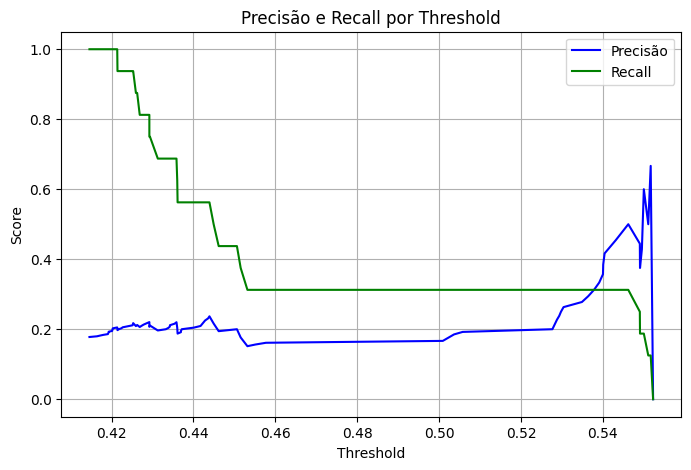

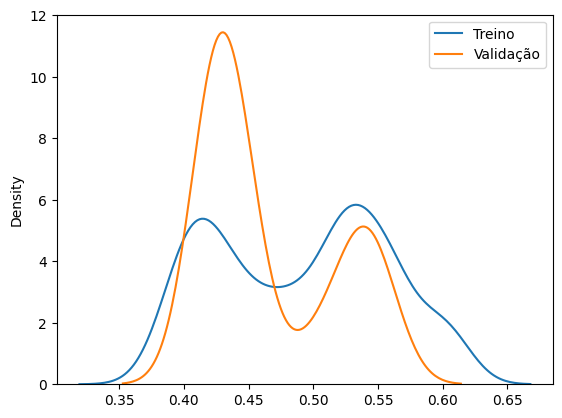

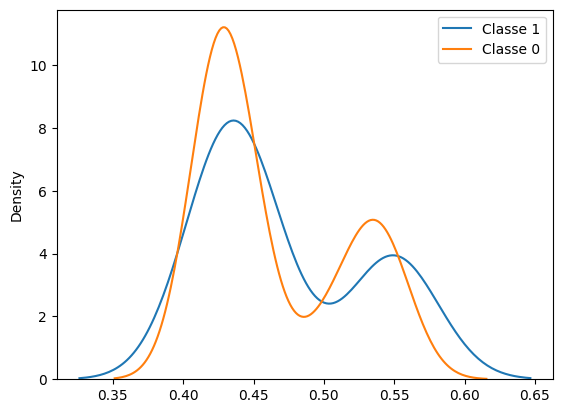

In [19]:
recall_minimo = 0.1  # mínimo de recall para considerar o modelo bom
resultado = tr.avaliar_e_logar_modelo(modelo, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

## Eliminação por correlação

In [25]:
X_filtrado, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
print("Features removidas por alta correlação:", removidas)

Features removidas por alta correlação: ['macd_hist_abs_mean', 'close_mean', 'macd_std', 'rsi_std', 'macd_signal_mean', 'dias_queda_pct', 'retorno_acumulado', 'ibov_std', 'close_min', 'macd_conf_mean', 'macd_conf_ultimo']


In [26]:
# Importâncias
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)


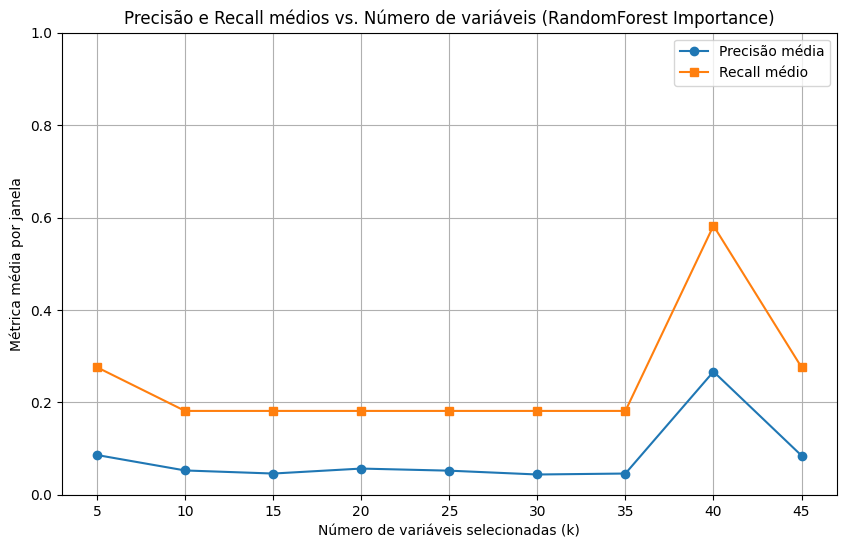

In [27]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


# Features reduzidas

In [22]:
n_features = 45
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['rsi_std',
 'ipca_ultimo',
 'rsi_volatilidade',
 'close_min',
 'retorno_medio_neg',
 'volume_std',
 'macd_signal_ultimo',
 'dolar_trend',
 'close_mean',
 'volume_mean',
 'close_dist_min',
 'macd_signal_mean',
 'dolar_std',
 'ibov_trend',
 'macd_hist_std',
 'macd_hist_abs_mean',
 'ibov_amplitude',
 'macd_conf_mean',
 'retorno_std',
 'retorno_medio_pos',
 'rsi_mean',
 'macd_hist_abs_ultimo',
 'macd_conf_ultimo',
 'ibov_std',
 'macd_mean',
 'macd_ultimo',
 'close_trend',
 'close_std',
 'retorno_mean',
 'volume_trend',
 'macd_signal_std',
 'dolar_ultimo',
 'close_max',
 'close_ult_vs_mm',
 'dias_alta_pct',
 'close_amplitude',
 'retorno_acumulado',
 'macd_hist_mean',
 'selic_ultimo',
 'macd_std',
 'dias_queda_pct',
 'macd_hist_ultimo',
 'rsi_ultimo',
 'retorno_desde_mudanca_close',
 'retorno_desde_mudanca_dolar']

In [23]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [30]:
modelo_reduzido = RandomForestClassifier(n_estimators=200,
                                        max_depth=5,
                                        #min_samples_split=50,
                                        min_samples_leaf=20,                                        
                                        max_features=0.2,
                                        random_state=42,
                                        n_jobs=-1
                                        )
modelo_reduzido.fit(X_train_reduzido.values, y_train.values)
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.935
AUC na validação: 0.678
Diferença AUC (Treino - Validação): 0.257
PROVÁVEL OVERFITTING


Avaliar e logar modelo
MLflow Run ID: 005176776fb94b97be533e8e09eca682 para VALE3.SA_60dias_x_0.03val_8dias_alvo
AUC no treino: 0.935
AUC na validação: 0.678

--- Conjunto de Treino --- Janelas

Threshold Ideal Selecionado: 0.52
  Precisão Média Esperada: 96.34%
  Recall Médio Esperado: 34.37%
  Janelas Usadas para Precisão: 235.0

Threshold ideal baseado em recall mínimo: 0.52

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 44.0
Sinais de compra previstos na validação: 0
Modelo VALE3.SA_60dias_x_0.03val_8dias_alvo salvo na run 005176776fb94b97be533e8e09eca682


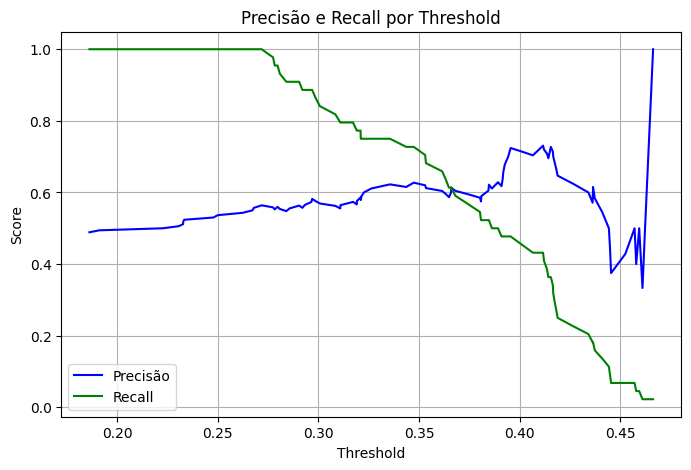

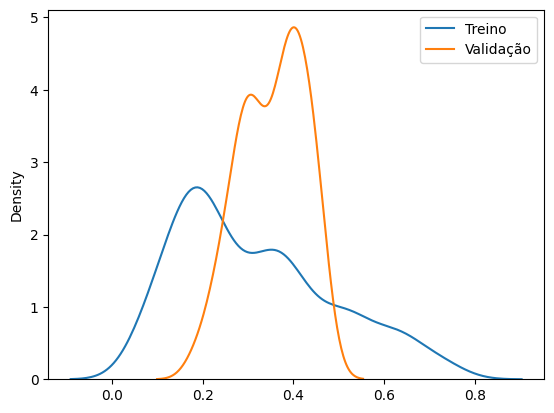

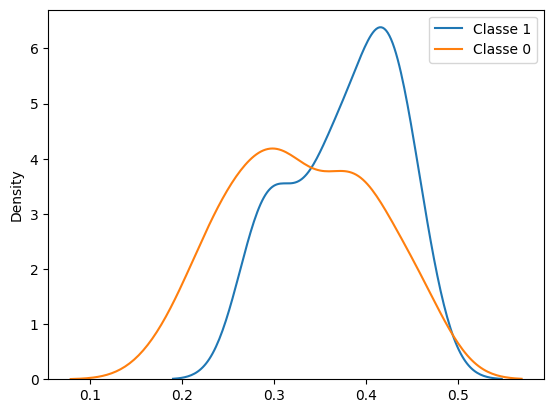

In [32]:
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=0.3)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

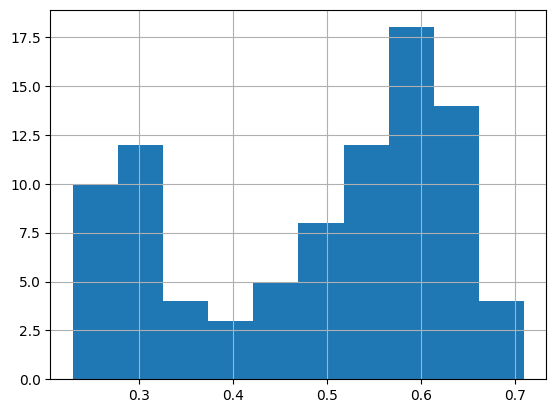

In [24]:
pd.Series(probas).hist()